In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
for folder in (DATA_DIR, MODEL_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR.resolve())
print("Data folder:", DATA_DIR.resolve())

Project folder: C:\Users\user\Downloads\MARIE BELLA\landslide_risk_monitor_project
Data folder: C:\Users\user\Downloads\MARIE BELLA\landslide_risk_monitor_project\data


In [3]:
excel_path = DATA_DIR / "Raw_Sensor_Data_Landslide_Monitoring.xlsx"
sample_path = DATA_DIR / "sample_landslide_data.csv"

if excel_path.exists():
    df = pd.read_excel(excel_path)
    data_source = "your sensor Excel file"
else:
    df = pd.read_csv(sample_path)
    data_source = "synthetic sample CSV"

print(f"Loaded {data_source}")
print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())

Loaded synthetic sample CSV
Shape: (600, 4)


,Soil_Moisture,Vibration,Rainfall,Landslide_Risk_Level
0,80.79,0.576,12.15,Medium
1,52.30,0.128,15.80,Low
2,87.98,0.238,23.17,Medium
3,74.28,0.015,19.19,Medium
4,23.01,0.052,1.36,Low


\nColumns: ['Soil_Moisture', 'Vibration', 'Rainfall', 'Landslide_Risk_Level']


In [4]:
# Standardise common column names from the sensor workbook
rename_map = {}
lower_to_original = {str(c).strip().lower(): c for c in df.columns}

def find_col(candidates):
    for candidate in candidates:
        if candidate.lower() in lower_to_original:
            return lower_to_original[candidate.lower()]
    return None

soil_col = find_col(["Soil_Moisture", "Soil20cm", "Soil Moisture", "soil_moisture"])
vibration_col = find_col(["Vibration", "Vibration_Value"])
rain_col = find_col(["Rainfall", "Raindrop", "Rain", "Rainfall_mm"])
label_col = find_col(["Landslide_Risk_Level", "Risk_Level", "LandslideRisk", "Label", "Risk"])

missing = []
if soil_col is None: missing.append("soil moisture (e.g. Soil_Moisture or Soil20cm)")
if vibration_col is None: missing.append("vibration (e.g. Vibration)")
if rain_col is None: missing.append("rainfall/raindrop reading (e.g. Rainfall or Raindrop)")
if missing:
    raise ValueError("Missing required input columns: " + ", ".join(missing) +
                     ". Check the Excel/CSV column names.")

prepared = pd.DataFrame({
    "Soil_Moisture": pd.to_numeric(df[soil_col], errors="coerce"),
    "Vibration": pd.to_numeric(df[vibration_col], errors="coerce"),
    "Rainfall": pd.to_numeric(df[rain_col], errors="coerce")
})

# Remove invalid/infinite feature values
prepared = prepared.replace([np.inf, -np.inf], np.nan)
valid = prepared.notna().all(axis=1)
prepared = prepared.loc[valid].copy()
source_labels = df.loc[valid, label_col].copy() if label_col is not None else None

if label_col is not None:
    prepared["Landslide_Risk_Level"] = source_labels.astype(str).str.strip().str.title()
    print(f"Using existing label column: {label_col}")
    print("Check that these labels are verified observations, not guesses.")
else:
    # Demo-only proxy rule. Normalize values to plausible ranges before scoring.
    soil_norm = prepared["Soil_Moisture"].clip(0, 100) / 100
    vibration_norm = prepared["Vibration"].clip(lower=0, upper=15) / 15
    rain_norm = prepared["Rainfall"].clip(lower=0, upper=120) / 120
    score = 0.50 * soil_norm + 0.30 * vibration_norm + 0.20 * rain_norm
    prepared["Landslide_Risk_Level"] = np.select(
        [score < 0.32, score < 0.57],
        ["Low", "Medium"],
        default="High"
    )
    print("WARNING: No verified risk label column was found.")
    print("Created PROXY labels from a rule. This is only for demonstrating the ML workflow.")

prepared = prepared.dropna(subset=["Landslide_Risk_Level"])
prepared = prepared[prepared["Landslide_Risk_Level"].isin(["Low", "Medium", "High"])]
if len(prepared) < 10:
    raise ValueError("Not enough valid rows for training (need at least 10).")
print("Prepared rows:", len(prepared))
display(prepared.head())
display(prepared["Landslide_Risk_Level"].value_counts().rename_axis("Risk level").to_frame("Rows"))

Using existing label column: Landslide_Risk_Level
Check that these labels are verified observations, not guesses.
Prepared rows: 600


,Soil_Moisture,Vibration,Rainfall,Landslide_Risk_Level
0,80.79,0.576,12.15,Medium
1,52.30,0.128,15.80,Low
2,87.98,0.238,23.17,Medium
3,74.28,0.015,19.19,Medium
4,23.01,0.052,1.36,Low


,Rows
Risk level,
Low,306
Medium,290
High,4


,Soil_Moisture,Vibration,Rainfall
count,600.000000,600.000000,600.000000
mean,57.158867,0.261252,14.150300
std,24.414083,0.329518,13.533293
min,15.460000,0.004000,0.030000
25%,35.120000,0.083750,4.915000
50%,57.480000,0.166000,10.785000
75%,78.772500,0.306000,18.745000
max,99.920000,3.970000,83.950000


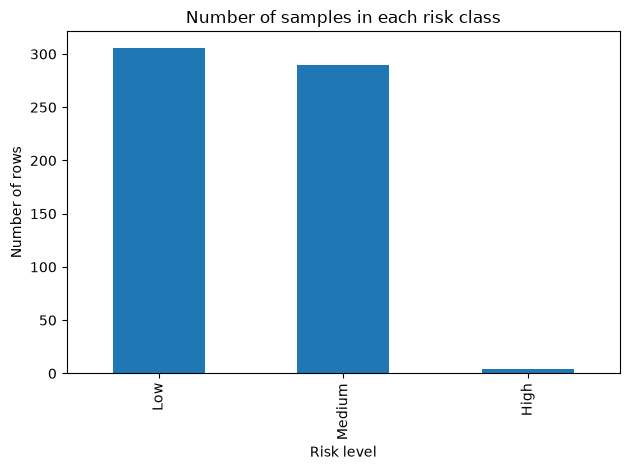

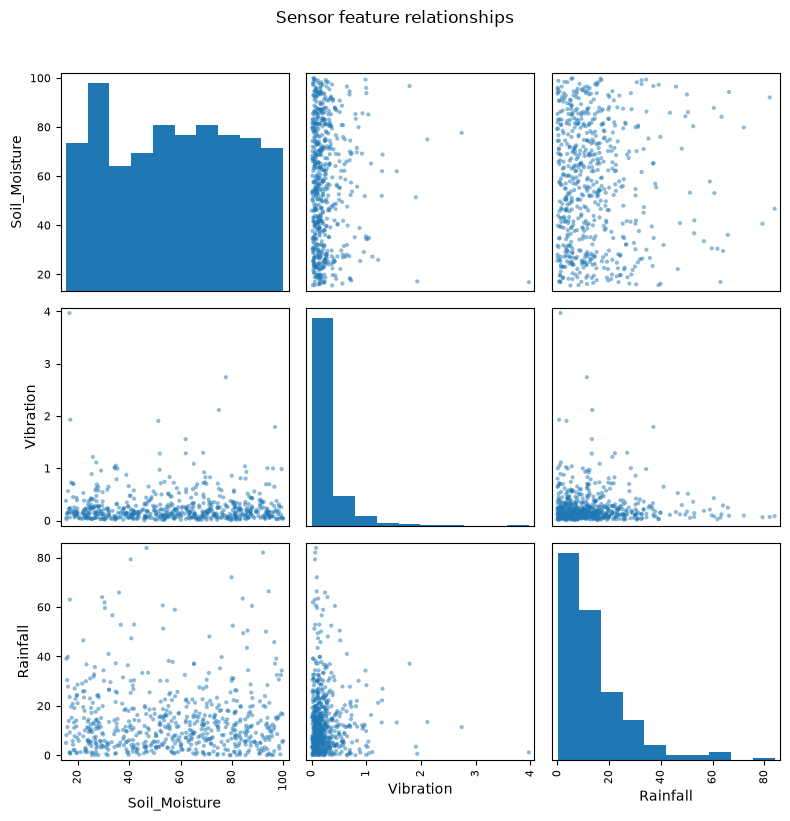

In [5]:
display(prepared[["Soil_Moisture", "Vibration", "Rainfall"]].describe())
prepared["Landslide_Risk_Level"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar")
plt.title("Number of samples in each risk class")
plt.xlabel("Risk level")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.show()

pd.plotting.scatter_matrix(prepared[["Soil_Moisture", "Vibration", "Rainfall"]], figsize=(8, 8), diagonal="hist")
plt.suptitle("Sensor feature relationships", y=1.02)
plt.tight_layout()
plt.show()

In [6]:
FEATURES = ["Soil_Moisture", "Vibration", "Rainfall"]
TARGET = "Landslide_Risk_Level"

X = prepared[FEATURES]
y = prepared[TARGET]

# Stratify when every class has at least 2 examples; otherwise use a regular split.
class_counts = y.value_counts()
stratify_y = y if len(class_counts) > 1 and class_counts.min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=stratify_y
)

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training complete.")

Training rows: 480
Testing rows: 120
Training complete.


Test accuracy: 0.975
\nClassification report:
              precision    recall  f1-score   support

         Low       0.97      1.00      0.98        61
      Medium       0.98      0.97      0.97        58
        High       0.00      0.00      0.00         1

    accuracy                           0.97       120
   macro avg       0.65      0.66      0.65       120
weighted avg       0.97      0.97      0.97       120



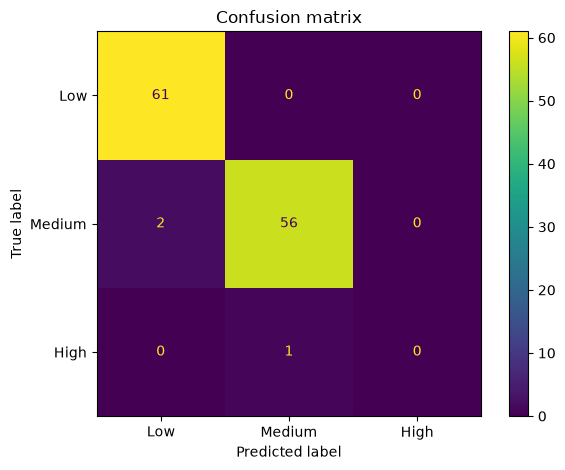

,Importance
Soil_Moisture,0.550755
Rainfall,0.273955
Vibration,0.175291


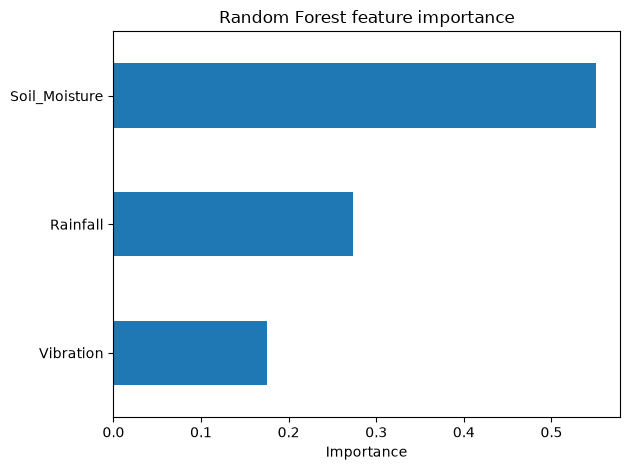

In [7]:
y_pred = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred, labels=["Low", "Medium", "High"], zero_division=0))

labels_present = [label for label in ["Low", "Medium", "High"] if label in set(y_test) | set(y_pred)]
cm = confusion_matrix(y_test, y_pred, labels=labels_present)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_present)
disp.plot(values_format="d")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(importance.rename("Importance").to_frame())
importance.sort_values().plot(kind="barh")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [8]:
# Example reading — change these values to your sensor measurements
new_reading = pd.DataFrame([{
    "Soil_Moisture": 78.0,  # e.g. percentage or calibrated sensor scale
    "Vibration": 3.2,       # sensor's vibration reading
    "Rainfall": 35.0        # rainfall amount or calibrated raindrop reading
}])

predicted_risk = model.predict(new_reading[FEATURES])[0]
print("Input reading:")
display(new_reading)
print("Predicted landslide risk level:", predicted_risk)

if hasattr(model, "predict_proba"):
    probabilities = pd.DataFrame([model.predict_proba(new_reading[FEATURES])[0]],
                                 columns=model.classes_)
    print("Model class probabilities (not a guarantee of real-world risk):")
    display(probabilities)

Input reading:


,Soil_Moisture,Vibration,Rainfall
0,78.0,3.2,35.0


Predicted landslide risk level: Medium
Model class probabilities (not a guarantee of real-world risk):


,High,Low,Medium
0,0.39,0.045,0.565


In [9]:
model_path = MODEL_DIR / "landslide_random_forest.joblib"
joblib.dump(model, model_path)

results = X_test.copy()
results["Actual_Label"] = y_test.values
results["Predicted_Label"] = y_pred
results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", header=["importance"])

print("Saved model to:", model_path.resolve())
print("Saved test predictions to:", (OUTPUT_DIR / "test_predictions.csv").resolve())
print("Saved feature importance to:", (OUTPUT_DIR / "feature_importance.csv").resolve())

Saved model to: C:\Users\user\Downloads\MARIE BELLA\landslide_risk_monitor_project\models\landslide_random_forest.joblib
Saved test predictions to: C:\Users\user\Downloads\MARIE BELLA\landslide_risk_monitor_project\outputs\test_predictions.csv
Saved feature importance to: C:\Users\user\Downloads\MARIE BELLA\landslide_risk_monitor_project\outputs\feature_importance.csv
